# DS2002 · Midterm Clinic Analysis and Charts

**Studio — 2026-10-28 · Fall 2026**  
**Class time:** 45 minutes

---

## Clinic — analysis and charts

Working session on your own project. The patterns below are the four analytical moves Questions 1 through 4 need; adapt each one to your cleaned data.

By the end of the hour you should have at least two charts you would be willing to put in the presentation on Monday.

### Pattern 1 — products moving together before landfall

One line per product, landfall marked. This is the Q1 chart, and it is the one that carries your presentation.

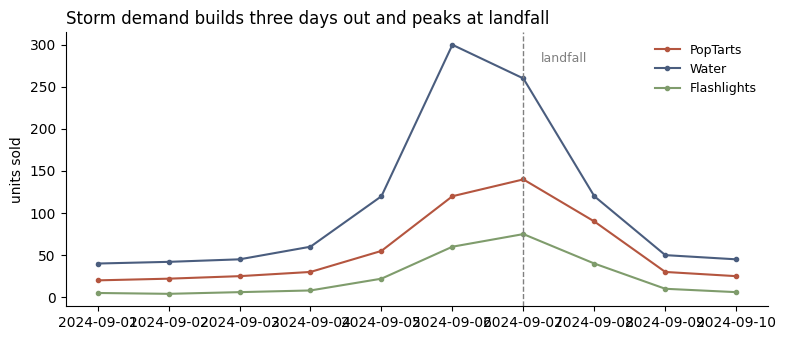

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt

daily = pd.DataFrame({
    'date': pd.date_range('2024-09-01', periods=10),
    'PopTarts': [20, 22, 25, 30, 55, 120, 140, 90, 30, 25],
    'Water': [40, 42, 45, 60, 120, 300, 260, 120, 50, 45],
    'Flashlights': [5, 4, 6, 8, 22, 60, 75, 40, 10, 6],
}).set_index('date')
landfall = pd.Timestamp('2024-09-07')

fig, ax = plt.subplots(figsize=(8, 3.5))
for col, color in zip(daily.columns, ['#b4553f', '#4a5d7e', '#7f9c6c']):
    ax.plot(daily.index, daily[col], marker='o', ms=3, color=color, label=col)
ax.axvline(landfall, ls='--', color='gray', lw=1)
ax.annotate('landfall', xy=(landfall + pd.Timedelta(hours=6), 280),
            fontsize=9, color='gray')
ax.set_title('Storm demand builds three days out and peaks at landfall',
             loc='left', fontsize=12)
ax.set_ylabel('units sold')
ax.legend(frameon=False, fontsize=9)
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

**TODO:** rebuild that with your own cleaned categories and your own landfall date. Title it with what your data actually shows — if your surge peaks a day early, say that.

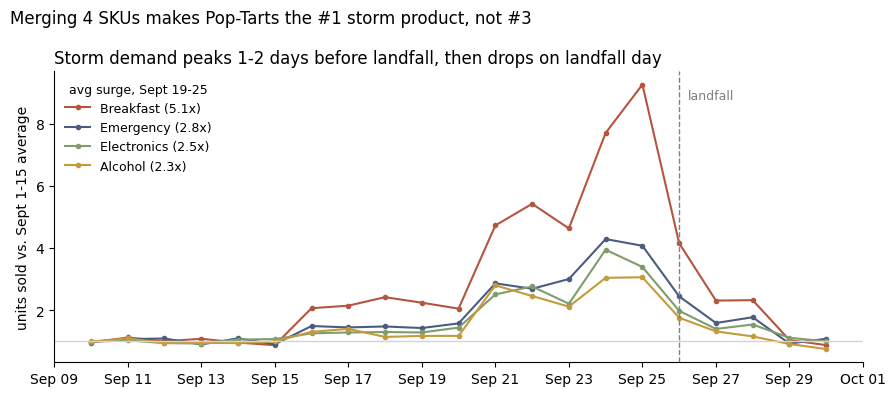

peak day per category:
category
Breakfast      Sep 25
Emergency      Sep 24
Electronics    Sep 24
Alcohol        Sep 25


In [10]:
# TODO
import matplotlib.dates as mdates

# Daily units by cleaned category (timestamped sales only, returns excluded)
t = txn[~txn['ts_missing'] & ~txn['is_return']]
by_cat = t.groupby(['date', 'category'])['quantity'].sum().unstack(fill_value=0)

# Scale each category to its own Sept 1-15 baseline so big and small categories share one axis
baseline = by_cat.loc['2024-09-01':'2024-09-15'].mean()
index = by_cat / baseline

# Plot the four categories with the biggest pre-landfall surge (Sept 19-25 vs baseline)
surge = index.loc['2024-09-19':'2024-09-25'].mean().sort_values(ascending=False)
top = surge.index[:4]
window = index.loc['2024-09-10':'2024-09-30', top]
peak_day = window.idxmax()

fig, ax = plt.subplots(figsize=(9, 4))
for col, color in zip(top, ['#b4553f', '#4a5d7e', '#7f9c6c', '#c49a3c']):
    ax.plot(window.index, window[col], marker='o', ms=3, color=color,
            label=f'{col} ({surge[col]:.1f}x)')
ax.axhline(1, color='lightgray', lw=1)
ax.axvline(LANDFALL, ls='--', color='gray', lw=1)
ax.annotate('landfall', xy=(LANDFALL + pd.Timedelta(hours=6), window.max().max() * 0.95),
            fontsize=9, color='gray')
ax.set_title('Storm demand peaks 1-2 days before landfall, then drops on landfall day',
             loc='left', fontsize=12)
ax.set_ylabel('units sold vs. Sept 1-15 average')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax.xaxis.set_major_locator(mdates.DayLocator(interval=2))
ax.legend(frameon=False, fontsize=9, title='avg surge, Sept 19-25', title_fontsize=9)
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
fig.suptitle('Merging 4 SKUs makes Pop-Tarts the #1 storm product, not #3', x=0.01, ha='left', fontsize=12)
plt.tight_layout()
plt.show()

print('peak day per category:')
print(peak_day.dt.strftime('%b %d').to_string())

### Pattern 2 — indexing to baseline so different products are comparable

Water outsells flashlights ten to one, so on a raw chart the flashlight surge is invisible. Divide each series by its own pre-storm average and every product starts at 1.0 — now you are comparing *how much each one moved*, which is the actual question.

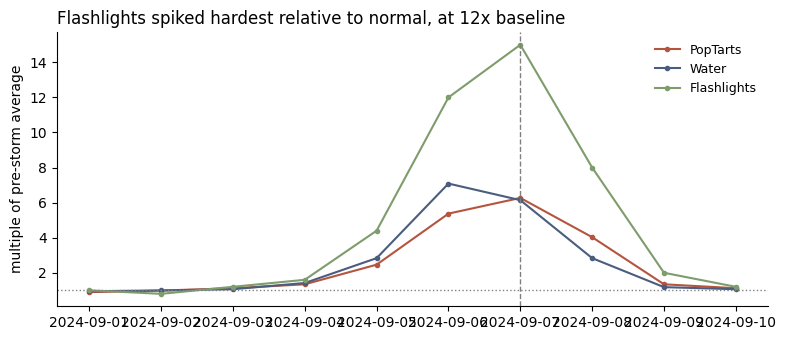

Flashlights    15.0
Water           7.1
PopTarts        6.3
dtype: float64


In [5]:
baseline = daily[daily.index < landfall - pd.Timedelta(days=3)].mean()
indexed = daily / baseline

fig, ax = plt.subplots(figsize=(8, 3.5))
for col, color in zip(indexed.columns, ['#b4553f', '#4a5d7e', '#7f9c6c']):
    ax.plot(indexed.index, indexed[col], marker='o', ms=3, color=color, label=col)
ax.axhline(1.0, ls=':', color='gray', lw=1)
ax.axvline(landfall, ls='--', color='gray', lw=1)
ax.set_title('Flashlights spiked hardest relative to normal, at 12x baseline',
             loc='left', fontsize=12)
ax.set_ylabel('multiple of pre-storm average')
ax.legend(frameon=False, fontsize=9)
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

print(indexed.max().round(1).sort_values(ascending=False))

Two charts, same data, different findings. The raw chart says water is the story; the indexed chart says flashlights are. Both belong in the presentation, in that order.

**TODO:** index your own products to their baseline and see whether your ranking changes.

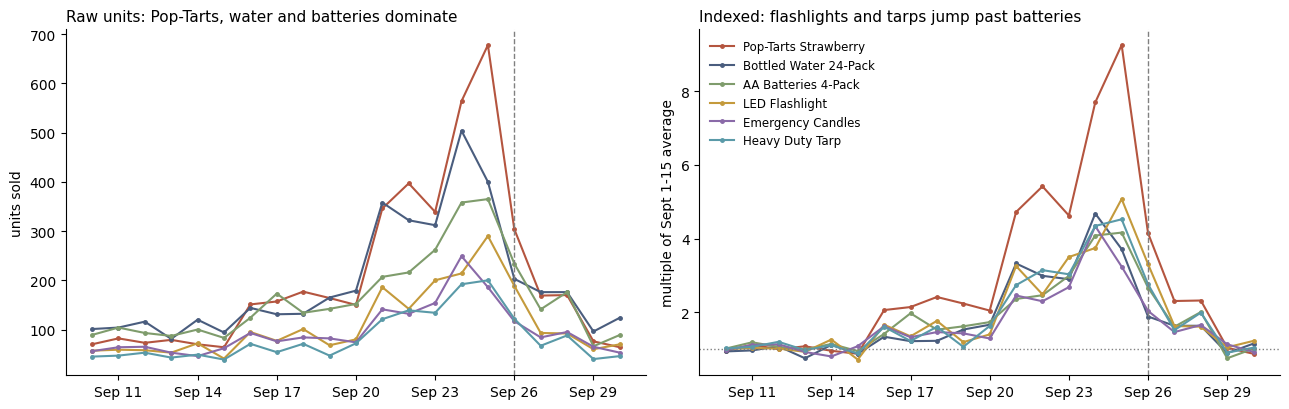

,baseline/day,raw peak,peak multiple,raw rank,indexed rank,moved
product_id,,,,,,
Pop-Tarts Strawberry,73,678,9.3,1,1,0
LED Flashlight,57,290,5.1,4,2,2
Bottled Water 24-Pack,108,504,4.7,2,3,-1
Heavy Duty Tarp,44,200,4.5,6,4,2
Emergency Candles,57,249,4.3,5,5,0
Monopoly Board Game,43,178,4.2,9,6,3
Portable Phone Charger,43,180,4.2,8,6,2
AA Batteries 4-Pack,88,365,4.2,3,6,-3
First Aid Kit,42,150,3.5,12,9,3


In [7]:
# TODOimport matplotlib.dates as mdates

# Daily units per canonical product (after the SKU merge), timestamped sales only, returns excluded
t = txn[~txn['ts_missing'] & ~txn['is_return']]
names = PRODUCTS.set_index('product_id')['product']
by_prod = t.groupby(['date', 'product_id'])['quantity'].sum().unstack(fill_value=0).rename(columns=names)

# Divide each product by its own Sept 1-15 average, so every product starts at 1.0
baseline = by_prod.loc['2024-09-01':'2024-09-15'].mean()
indexed = by_prod / baseline

# Rank all 20 products two ways over the storm window: raw peak units vs peak multiple of baseline
storm = slice('2024-09-16', '2024-09-30')
ranks = pd.DataFrame({
    'baseline/day': baseline.round(0).astype(int),
    'raw peak': by_prod.loc[storm].max().astype(int),
    'peak multiple': indexed.loc[storm].max().round(1),
})
ranks['raw rank'] = ranks['raw peak'].rank(ascending=False, method='min').astype(int)
ranks['indexed rank'] = ranks['peak multiple'].rank(ascending=False, method='min').astype(int)
ranks['moved'] = ranks['raw rank'] - ranks['indexed rank']
ranks = ranks.sort_values('indexed rank')

# Chart the top 5 by either ranking, raw next to indexed
show = list(dict.fromkeys(ranks.nsmallest(5, 'raw rank').index.tolist()
                          + ranks.nsmallest(5, 'indexed rank').index.tolist()))
colors = ['#b4553f', '#4a5d7e', '#7f9c6c', '#c49a3c', '#8a6aa8', '#5a9aa8', '#999999']
window = slice('2024-09-10', '2024-09-30')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2), sharex=True)
for col, color in zip(show, colors):
    ax1.plot(by_prod.loc[window].index, by_prod.loc[window, col], marker='o', ms=2.5, color=color, label=col)
    ax2.plot(indexed.loc[window].index, indexed.loc[window, col], marker='o', ms=2.5, color=color, label=col)
ax1.set_title('Raw units: Pop-Tarts, water and batteries dominate', loc='left', fontsize=11)
ax1.set_ylabel('units sold')
ax2.set_title('Indexed: flashlights and tarps jump past batteries', loc='left', fontsize=11)
ax2.set_ylabel('multiple of Sept 1-15 average')
ax2.axhline(1, ls=':', color='gray', lw=1)
for ax in (ax1, ax2):
    ax.axvline(LANDFALL, ls='--', color='gray', lw=1)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
    ax.xaxis.set_major_locator(mdates.DayLocator(interval=3))
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)
ax2.legend(frameon=False, fontsize=8.5, loc='upper left')
plt.tight_layout()
plt.show()

ranks

### Pattern 3 — before-and-after for Q2

The SKU consolidation question needs a comparison, not a description. Show the number somebody would have reported without your work next to the number with it.

In [ ]:
fragmented = pd.Series({'PT-12': 40, 'SKU#459812': 15, 'POPTART-STRAW': 22})
consolidated = pd.Series({'POPTART-STRAW': 77})

fig, axes = plt.subplots(1, 2, figsize=(9, 3), sharey=True)
axes[0].bar(fragmented.index, fragmented.values, color='#c9cdd6')
axes[0].set_title('As recorded: three unremarkable SKUs', fontsize=10, loc='left')
axes[0].tick_params(axis='x', labelrotation=20)
axes[1].bar(consolidated.index, consolidated.values, color='#b4553f')
axes[1].set_title('Consolidated: one product, 77 units', fontsize=10, loc='left')
axes[0].set_ylabel('units')
for ax in axes:
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

**TODO:** build this for your largest consolidated product family. State the multiple.

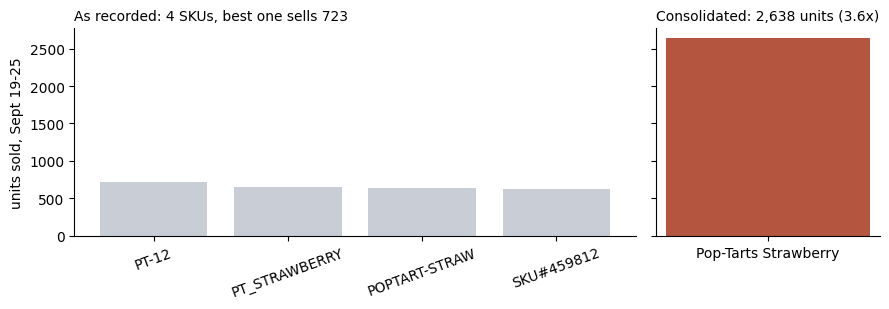

Pop-Tarts Strawberry: 4 SKUs merged into one product
Largest single SKU: PT-12 = 723 units
Consolidated: 2,638 units = 3.6x what the biggest SKU shows (377 per day)
Rank among sellers that week: #3 as a raw SKU -> #1 of 20 products after the merge


In [8]:
# Units per raw SKU in the 7 days before landfall (Sept 19-25), timestamped sales, returns excluded
t = txn[~txn['ts_missing'] & ~txn['is_return']]
week = t[(t['date'] >= '2024-09-19') & (t['date'] <= '2024-09-25')]
by_sku = week.groupby(['product_id', 'sku'])['quantity'].sum()

# Largest consolidated family = the product that was split across the most SKUs (ties -> more units)
fam = by_sku.groupby(level=0).agg(['count', 'sum']).sort_values(['count', 'sum'], ascending=False)
pid = fam.index[0]
name = PRODUCTS.set_index('product_id').loc[pid, 'product']
fragmented = by_sku.loc[pid].sort_values(ascending=False)
consolidated = fragmented.sum()
multiple = consolidated / fragmented.max()

# Where the family ranks among all products, before and after the merge
raw_rank = (by_sku.droplevel(0).sort_values(ascending=False).index.get_loc(fragmented.index[0]) + 1)
clean_rank = int(by_sku.groupby(level=0).sum().rank(ascending=False, method='min')[pid])

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True,
                         gridspec_kw={'width_ratios': [len(fragmented), 1.6]})
axes[0].bar(fragmented.index, fragmented.values, color='#c9cdd6')
axes[0].set_title(f'As recorded: {len(fragmented)} SKUs, best one sells {fragmented.max():,}',
                  fontsize=10, loc='left')
axes[0].tick_params(axis='x', labelrotation=20)
axes[0].set_ylabel('units sold, Sept 19-25')
axes[1].bar([name], [consolidated], color='#b4553f')
axes[1].set_title(f'Consolidated: {consolidated:,} units ({multiple:.1f}x)', fontsize=10, loc='left')
for ax in axes:
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

print(f'{name}: {len(fragmented)} SKUs merged into one product')
print(f'Largest single SKU: {fragmented.idxmax()} = {fragmented.max():,} units')
print(f'Consolidated: {consolidated:,} units = {multiple:.1f}x what the biggest SKU shows '
      f'({consolidated / 7:,.0f} per day)')
print(f'Rank among sellers that week: #{raw_rank} as a raw SKU -> #{clean_rank} of 20 products after the merge')

### Pattern 4 — Q4, stores by distance

Aggregate by store, join whatever geography you have, and look for the gradient. Watch the group sizes — a store with four transactions will produce a wild average.

In [ ]:
by_store = pd.DataFrame({
    'store_id': ['FL-105', 'FL-239', 'FL-411', 'FL-502'],
    'surge_multiple': [3.4, 2.9, 1.6, 1.1],
    'miles_from_path': [12, 38, 120, 260],
    'transactions': [4200, 3100, 2800, 90],
})

fig, ax = plt.subplots(figsize=(7, 3.5))
sizes = by_store['transactions'] / 15
ax.scatter(by_store['miles_from_path'], by_store['surge_multiple'],
           s=sizes, alpha=0.7, color='#4a5d7e')
for row in by_store.itertuples():
    ax.annotate(row.store_id, (row.miles_from_path, row.surge_multiple),
                textcoords='offset points', xytext=(8, 4), fontsize=9)
ax.set_title('Surge falls off with distance from the storm path',
             loc='left', fontsize=12)
ax.set_xlabel('miles from storm path')
ax.set_ylabel('surge multiple vs baseline')
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

print('note the smallest bubble: FL-502 has only 90 transactions,')
print('so its 1.1x is barely distinguishable from noise.')

Sizing the points by transaction count is doing real work here — it tells the reader which points to trust. A four-point scatter is not a trend line, and you should say so out loud rather than fitting one.

**TODO:** build your version. If you only have a handful of stores, present it as a table with a comment instead of a scatter — a chart with five points and a regression line will get asked about.

In [9]:
# TODO
# Helene landfall point (NHC, 11:10 PM EDT Sept 26): Big Bend, ~10 mi WSW of Perry
LANDFALL_LAT, LANDFALL_LON = 30.0, -83.7

def miles_from_landfall(lat, lon):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat, lon, LANDFALL_LAT, LANDFALL_LON])
    a = np.sin((lat2 - lat1) / 2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2)**2
    return 3958.8 * 2 * np.arcsin(np.sqrt(a))

# Daily units per store (timestamped sales, returns excluded)
t = txn[~txn['ts_missing'] & ~txn['is_return']]
daily = t.groupby(['date', 'store_id'])['quantity'].sum().unstack(fill_value=0)
base = daily.loc['2024-09-01':'2024-09-15'].mean()
idx = daily / base

by_store = stores.set_index('store_id')[['city', 'region', 'latitude', 'longitude']].copy()
by_store['miles'] = miles_from_landfall(by_store.latitude, by_store.longitude).round(0).astype(int)
by_store['transactions'] = t.groupby('store_id')['transaction_id'].nunique()
by_store['surge_multiple'] = idx.loc['2024-09-19':'2024-09-25'].mean().round(2)
by_store['peak_day'] = idx.loc['2024-09-16':'2024-09-30'].idxmax().dt.strftime('%b %d')
by_store['first_2x_day'] = (idx.loc['2024-09-16':'2024-09-30'] >= 2).idxmax().dt.strftime('%b %d')
by_store['vs_median'] = (by_store.surge_multiple / by_store.surge_multiple.median()).round(2)

table = (by_store.drop(columns=['latitude', 'longitude'])
                 .sort_values('miles')
                 .rename(columns={'miles': 'miles from landfall',
                                  'surge_multiple': 'surge (Sept 19-25 vs Sept 1-15)',
                                  'first_2x_day': 'first day >= 2x',
                                  'vs_median': 'vs median store'}))

print(f"Spearman rank correlation, distance vs surge: "
      f"{by_store['miles'].corr(by_store['surge_multiple'], method='spearman'):.2f}  (n = {len(by_store)} stores)")
table

Spearman rank correlation, distance vs surge: -0.13  (n = 12 stores)


,city,region,miles from landfall,transactions,surge (Sept 19-25 vs Sept 1-15),peak_day,first day >= 2x,vs median store
store_id,,,,,,,,
FL-619,Tallahassee,Panhandle,46,1981,2.60,Sep 24,Sep 21,1.06
FL-078,Gainesville,North,86,2001,2.37,Sep 25,Sep 22,0.97
FL-412,Jacksonville,North,124,2028,2.49,Sep 25,Sep 21,1.02
FL-105,Tampa,West,160,2043,2.53,Sep 25,Sep 21,1.03
FL-445,St. Petersburg,West,167,2074,2.45,Sep 24,Sep 21,1.00
FL-156,Daytona Beach,East,170,2074,2.41,Sep 24,Sep 21,0.99
FL-302,Lakeland,Central,172,2123,2.49,Sep 25,Sep 21,1.02
FL-239,Orlando,Central,173,2010,2.23,Sep 24,Sep 21,0.91
FL-287,Kissimmee,Central,182,2053,2.42,Sep 25,Sep 21,0.99


### Before you leave

- At least two presentation-ready charts, each with a message title
- Q1 has a stated baseline window and a multiple
- Q2 has a before-and-after comparison
- Everything pushed

Monday is presentations. The timing breakdown and the self-check are in Monday's notebook — read it tonight, not Monday morning.

---

## Checkpoint (participation)

Report the surge multiple you found for your top product and the baseline window you used to get it.

Work in groups if you wish, then fill in the cell below **yourself**. Paste the printed output (or a screenshot of it) into this week's **Studio Checkpoint** in Canvas by **Thursday 11:59pm ET**. One submission per person, not per group.

In [ ]:
# Checkpoint
top_product = 'TODO'         # TODO: your biggest mover
surge_multiple = None        # TODO: how many times baseline
baseline_window = 'TODO'     # TODO: e.g. '14 days before Sept 4'
charts_ready = None          # TODO: how many presentation-ready charts you have

print('top product:', top_product)
print('surge multiple:', surge_multiple)
print('baseline window:', baseline_window)
print('charts ready:', charts_ready)